In [1]:
# If you are on Google Colab or a fresh environment, uncomment and run:
%pip install "numpy>=2.3.2" "qiskit==2.5.1" "qiskit-aer==0.17.2" \
     "qiskit-addon-sqd==0.12.1" "ffsim>=0.0.81" "pyscf==2.14.0" \
     "matplotlib==3.11.1" "pylatexenc==2.10"

from collections import Counter
from math import comb

import numpy as np
import matplotlib.pyplot as plt
import pyscf
import pyscf.ao2mo
import pyscf.cc
import pyscf.mcscf
import ffsim
from qiskit import QuantumCircuit
from qiskit.primitives import BitArray
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_addon_sqd.fermion import diagonalize_fermionic_hamiltonian

rng = np.random.default_rng(2026)

In [2]:
from importlib.metadata import version
import numpy as np
import matplotlib.pyplot as plt
import pyscf
import ffsim

from qiskit import QuantumCircuit
from qiskit.primitives import BitArray
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_addon_sqd.fermion import diagonalize_fermionic_hamiltonian

print("NumPy:", np.__version__)
print("PySCF:", pyscf.__version__)
print("FFSim:", version("ffsim"))
print("All major imports successful!")

NumPy: 2.5.4
PySCF: 2.14.0
FFSim: 0.0.84
All major imports successful!


In [3]:
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt
import pyscf
import ffsim

from qiskit import QuantumCircuit
from qiskit.primitives import BitArray
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_addon_sqd.fermion import diagonalize_fermionic_hamiltonian

print("NumPy:", np.__version__)
print("PySCF:", pyscf.__version__)
print("FFSim:", version("ffsim"))
print("Qiskit:", version("qiskit"))
print("Qiskit Aer:", version("qiskit-aer"))
print("Qiskit SQD:", version("qiskit-addon-sqd"))
print("All major imports successful!")

NumPy: 2.5.4
PySCF: 2.14.0
FFSim: 0.0.84
Qiskit: 2.5.1
Qiskit Aer: 0.17.2
Qiskit SQD: 0.12.1
All major imports successful!


In [4]:
def build_active_space_problem(atom, basis="sto-3g", n_frozen=0, compare_to_fci=True):
    """Build a small closed-shell active-space chemistry problem."""
    mol = pyscf.gto.Mole()
    mol.build(atom=atom, basis=basis, verbose=0)
    assert mol.nelectron % 2 == 0, "this teaching helper expects a closed-shell molecule"

    scf = pyscf.scf.RHF(mol).run()
    active_orbitals = list(range(n_frozen, mol.nao_nr()))
    norb = len(active_orbitals)
    n_active_electrons = int(round(np.sum(scf.mo_occ[active_orbitals])))
    n_alpha = (n_active_electrons + mol.spin) // 2
    n_beta = (n_active_electrons - mol.spin) // 2
    nelec = (n_alpha, n_beta)

    # CASCI is used here only as a convenient active-space integral transformer.
    cas = pyscf.mcscf.CASCI(scf, norb, nelec)
    mo = cas.sort_mo(active_orbitals, base=0)
    hcore, e_core = cas.get_h1cas(mo)
    eri = pyscf.ao2mo.restore(1, cas.get_h2cas(mo), norb)

    frozen = [index for index in range(mol.nao_nr()) if index not in active_orbitals] or None
    ccsd = pyscf.cc.CCSD(scf, frozen=frozen).run()
    e_fci = cas.kernel(mo)[0] if compare_to_fci else None

    return {
        "atom": atom,
        "basis": basis,
        "n_frozen": n_frozen,
        "mol": mol,
        "scf": scf,
        "ccsd": ccsd,
        "norb": norb,
        "nelec": nelec,
        "hcore": hcore,
        "eri": eri,
        "e_core": e_core,
        "e_hf": scf.e_tot,
        "e_ccsd": ccsd.e_tot,
        "e_fci": e_fci,
    }


def print_problem_summary(problem):
    print(f"active orbitals: {problem['norb']} | electrons: {problem['nelec']} | "
          f"qubits: {2 * problem['norb']}")
    if problem["e_fci"] is not None:
        reference = problem["e_fci"]
        print(f"Hartree-Fock : {problem['e_hf']:.6f} Ha | error {(problem['e_hf'] - reference) * 1000:+8.2f} mHa")
        print(f"CCSD         : {problem['e_ccsd']:.6f} Ha | error {(problem['e_ccsd'] - reference) * 1000:+8.2f} mHa")
        print(f"exact (FCI)  : {reference:.6f} Ha")
    else:
        print(f"Hartree-Fock : {problem['e_hf']:.6f} Ha")
        print(f"CCSD         : {problem['e_ccsd']:.6f} Ha")


bond = 1.5
n2_atom = [["N", (0, 0, 0)], ["N", (bond, 0, 0)]]
problem = build_active_space_problem(n2_atom, basis="sto-3g", n_frozen=2, compare_to_fci=True)
print_problem_summary(problem)

norb = problem["norb"]
nelec = problem["nelec"]
n_alpha, n_beta = nelec
hcore, eri, e_core = problem["hcore"], problem["eri"], problem["e_core"]
e_hf, e_ccsd, e_fci = problem["e_hf"], problem["e_ccsd"], problem["e_fci"]

active orbitals: 8 | electrons: (5, 5) | qubits: 16
Hartree-Fock : -107.272449 Ha | error  +309.03 mHa
CCSD         : -107.567708 Ha | error   +13.77 mHa
exact (FCI)  : -107.581483 Ha


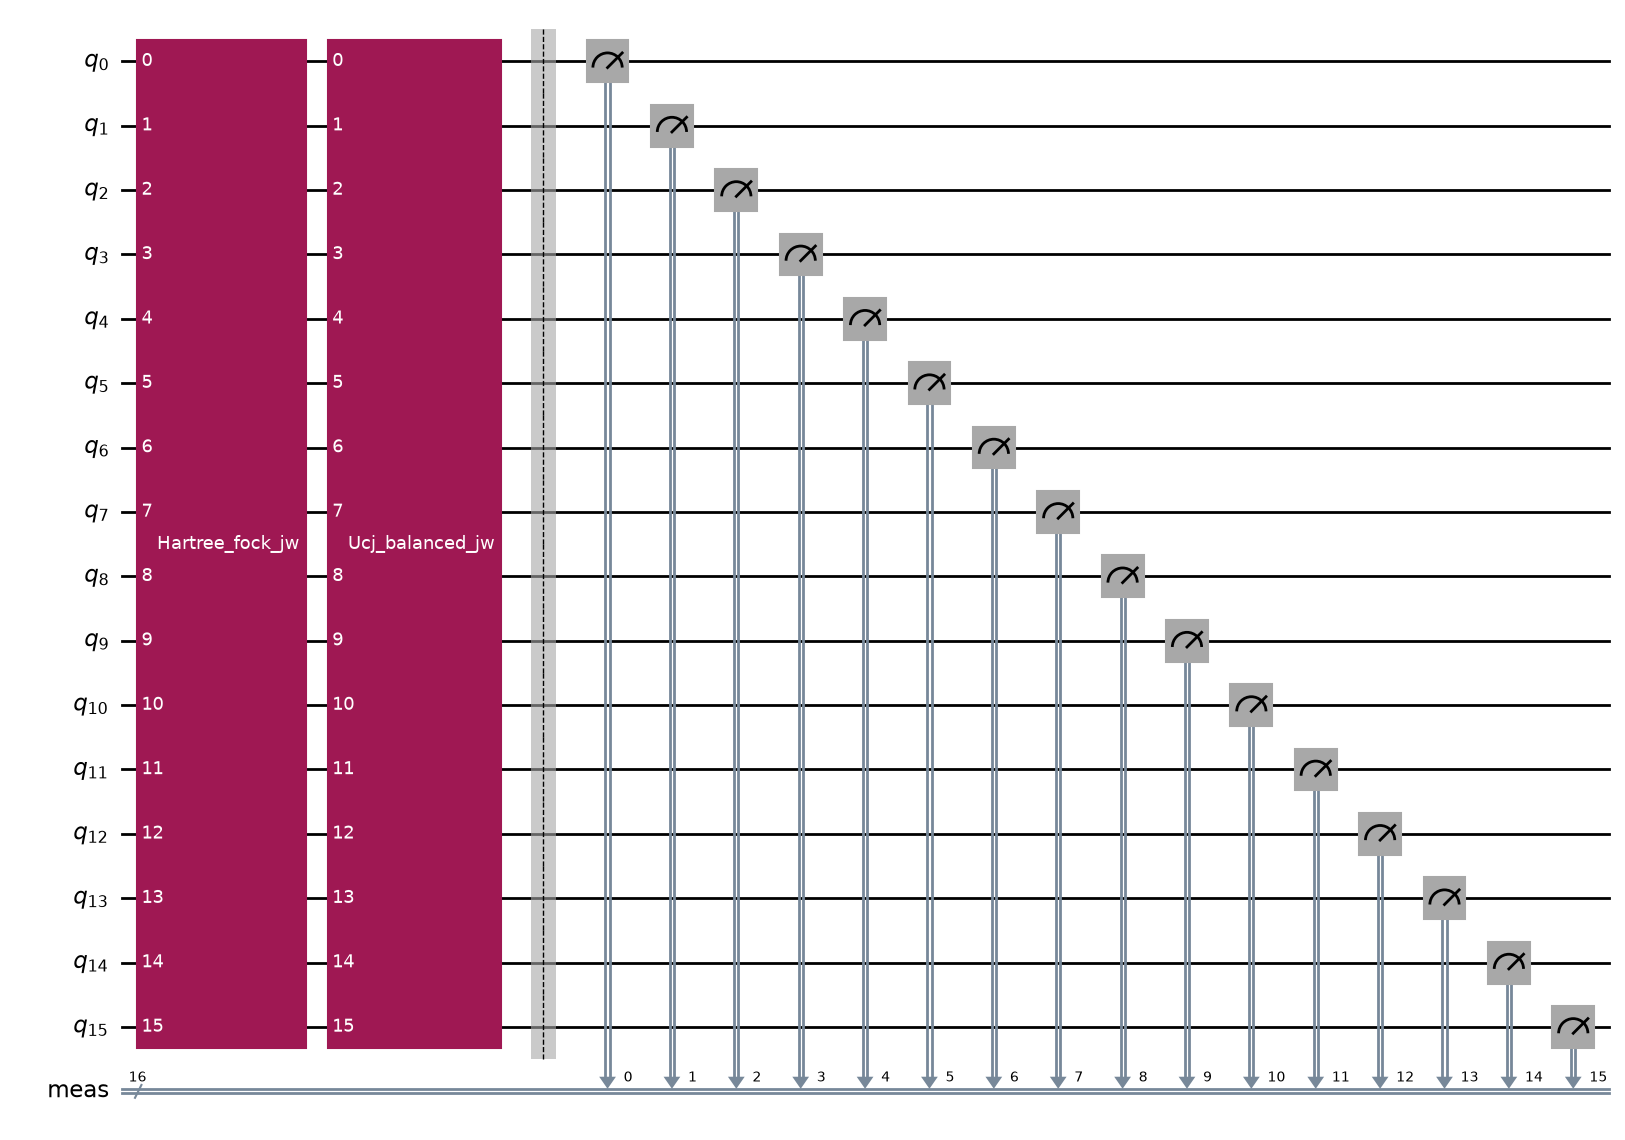

In [5]:
def build_ansatz(problem, n_reps=2, measure=True):
    """Build a spin-balanced UCJ ansatz initialized from the problem's CCSD amplitudes."""
    norb = problem["norb"]
    nelec = problem["nelec"]
    ccsd = problem["ccsd"]

    ucj_op = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
        t2=ccsd.t2,
        t1=ccsd.t1,
        n_reps=n_reps,
    )
    circuit = QuantumCircuit(2 * norb)
    circuit.append(ffsim.qiskit.PrepareHartreeFockJW(norb, nelec), circuit.qubits)
    circuit.append(ffsim.qiskit.UCJOpSpinBalancedJW(ucj_op), circuit.qubits)
    if measure:
        circuit.measure_all()
    return circuit


circuit = build_ansatz(problem, n_reps=2, measure=True)
circuit.draw("mpl", fold=-1)

In [6]:
def sample_circuit(circuit, shots=20_000, seed=123, optimization_level=1):
    """Compile and sample a measured circuit on Aer."""
    backend = AerSimulator()
    pass_manager = generate_preset_pass_manager(
        optimization_level=optimization_level,
        backend=backend,
    )
    isa_circuit = pass_manager.run(circuit)
    two_qubit_gates = sum(
        1 for instruction in isa_circuit.data if instruction.operation.num_qubits == 2
    )
    bit_array = (
        SamplerV2(seed=seed)
        .run([isa_circuit], shots=shots)
        .result()[0]
        .data.meas
    )
    strings = bit_array.get_bitstrings()
    return {
        "backend": backend,
        "isa_circuit": isa_circuit,
        "bit_array": bit_array,
        "strings": strings,
        "shots": shots,
        "depth": isa_circuit.depth(),
        "two_qubit_gates": two_qubit_gates,
    }


sample_record = sample_circuit(circuit, shots=20_000, seed=123)
bit_array = sample_record["bit_array"]
strings = sample_record["strings"]
shots = sample_record["shots"]

print(f"compiled circuit: depth {sample_record['depth']}, "
      f"{sample_record['two_qubit_gates']} two-qubit gates")
print(f"{bit_array.num_shots:,} shots x {bit_array.num_bits} bits, "
      f"{len(set(strings)):,} distinct sampled rows")

compiled circuit: depth 156, 604 two-qubit gates
20,000 shots x 16 bits, 125 distinct sampled rows


In [7]:
def bitstrings_to_bool(strings):
    return np.asarray([[character == "1" for character in string] for string in strings], dtype=bool)


def valid_electron_counts(bitstrings, norb, nelec):
    """Mask rows with the target alpha count on the right and beta count on the left."""
    bitstrings = np.asarray(bitstrings, dtype=bool)
    alpha_ok = bitstrings[:, norb:].sum(axis=1) == nelec[0]
    beta_ok = bitstrings[:, :norb].sum(axis=1) == nelec[1]
    return alpha_ok & beta_ok


def pretty(s):
    return s[:norb] + "·" + s[norb:]


bools_clean = bitstrings_to_bool(strings)
clean_valid = valid_electron_counts(bools_clean, norb, nelec)
assert clean_valid.all(), "the noiseless number-conserving ansatz should return only valid rows"
print(f"valid electron counts: {clean_valid.mean():.0%}")

valid electron counts: 100%


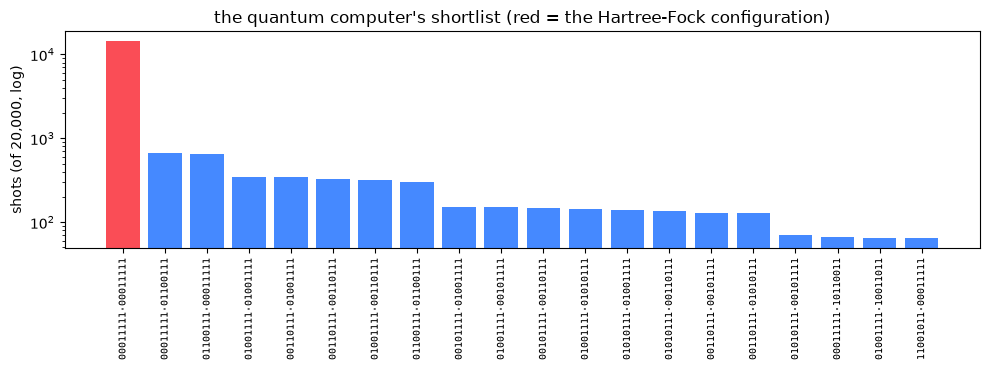

In [8]:
def pretty(s):
    return s[:norb] + "·" + s[norb:]  # visual split: beta·alpha


hf_string = "0" * (norb - n_alpha) + "1" * n_alpha
hf_full = hf_string + hf_string

top = Counter(strings).most_common(20)
colors = ["#fa4d56" if s == hf_full else "#4589ff" for s, _ in top]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(len(top)), [c for _, c in top], color=colors)
ax.set_yscale("log")
ax.set_xticks(range(len(top)))
ax.set_xticklabels([pretty(s) for s, _ in top], rotation=90, fontsize=7, family="monospace")
ax.set_ylabel(f"shots (of {shots:,}, log)")
ax.set_title("the quantum computer's shortlist (red = the Hartree-Fock configuration)")
plt.tight_layout()
plt.show()

probability no bit flips at all:       72.4%
probability electron counts stay valid: 73.3% (exact model calculation)
observed valid fraction:                73.1%


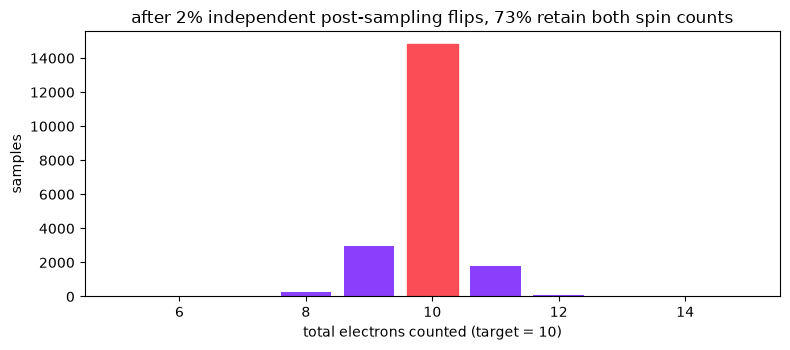

In [9]:
def add_bit_flip_noise(bit_array, probability, seed=2026):
    """Apply independent post-sampling bit flips and return a new BitArray plus booleans."""
    clean = bitstrings_to_bool(bit_array.get_bitstrings())
    local_rng = np.random.default_rng(seed)
    noisy = clean ^ (local_rng.random(clean.shape) < probability)
    return BitArray.from_bool_array(noisy, order="big"), noisy


def fixed_count_probability(norb, n_occupied, probability):
    """Probability that one spin sector keeps its Hamming weight after independent flips."""
    n_empty = norb - n_occupied
    return sum(
        comb(n_occupied, k)
        * comb(n_empty, k)
        * probability ** (2 * k)
        * (1 - probability) ** (norb - 2 * k)
        for k in range(min(n_occupied, n_empty) + 1)
    )


def valid_count_probability(norb, nelec, probability):
    return (
        fixed_count_probability(norb, nelec[0], probability)
        * fixed_count_probability(norb, nelec[1], probability)
    )


noise_p = 0.02
noisy_bit_array, noisy_bools = add_bit_flip_noise(bit_array, noise_p, seed=2026)
noisy_valid = valid_electron_counts(noisy_bools, norb, nelec)
electrons_measured = noisy_bools.sum(axis=1)

p_untouched = (1 - noise_p) ** (2 * norb)
p_valid_theory = valid_count_probability(norb, nelec, noise_p)
print(f"probability no bit flips at all:       {p_untouched:.1%}")
print(f"probability electron counts stay valid: {p_valid_theory:.1%} (exact model calculation)")
print(f"observed valid fraction:                {noisy_valid.mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.6))
counts_w = np.bincount(electrons_measured, minlength=2 * norb + 1)
bars = ax.bar(range(len(counts_w)), counts_w, color="#8a3ffc")
bars[n_alpha + n_beta].set_color("#fa4d56")
ax.set_xlim(4.5, 15.5)
ax.set_xlabel(f"total electrons counted (target = {n_alpha + n_beta})")
ax.set_ylabel("samples")
ax.set_title(f"after {noise_p:.0%} independent post-sampling flips, "
             f"{noisy_valid.mean():.0%} retain both spin counts")
plt.tight_layout()
plt.show()

In [10]:
def recover_and_diagonalize(
    problem,
    bit_array,
    *,
    label,
    samples_per_batch=500,
    num_batches=3,
    max_iterations=6,
    symmetrize_spin=False,
    seed=31415,
    verbose=True,
):
    """Run SQD and return a transparent record of energies and subspace dimensions."""
    history = []

    def callback(results):
        best = min(results, key=lambda result: result.energy)
        batch_shapes = [tuple(int(x) for x in result.sci_state.amplitudes.shape) for result in results]
        batch_dimensions = [int(np.prod(shape)) for shape in batch_shapes]
        total_energy = best.energy + problem["e_core"]
        history.append({
            "energy": total_energy,
            "batch_shapes": batch_shapes,
            "batch_dimensions": batch_dimensions,
        })
        if verbose:
            reference_text = ""
            if problem["e_fci"] is not None:
                reference_text = f" | error {(total_energy - problem['e_fci']) * 1000:+7.2f} mHa"
            print(f"  {label}, iteration {len(history)}: E = {total_energy:.6f} Ha{reference_text} "
                  f"| batch dimensions {batch_dimensions}")

    result = diagonalize_fermionic_hamiltonian(
        problem["hcore"],
        problem["eri"],
        bit_array,
        samples_per_batch=samples_per_batch,
        norb=problem["norb"],
        nelec=problem["nelec"],
        num_batches=num_batches,
        energy_tol=0.0,
        occupancies_tol=0.0,
        max_iterations=max_iterations,
        symmetrize_spin=symmetrize_spin,
        callback=callback,
        seed=seed,
    )

    energy = result.energy + problem["e_core"]
    final_shape = tuple(int(x) for x in result.sci_state.amplitudes.shape)
    strings = bit_array.get_bitstrings()
    error_mha = None if problem["e_fci"] is None else (energy - problem["e_fci"]) * 1000
    return {
        "label": label,
        "result": result,
        "energy": energy,
        "error_mha": error_mha,
        "history": history,
        "distinct_sample_rows": len(set(strings)),
        "final_shape": final_shape,
        "final_dimension": int(np.prod(final_shape)),
        "settings": {
            "samples_per_batch": samples_per_batch,
            "num_batches": num_batches,
            "max_iterations": max_iterations,
            "symmetrize_spin": symmetrize_spin,
            "seed": seed,
        },
    }

In [11]:
CONTROL_SETTINGS = {
    "samples_per_batch": 500,
    "num_batches": 3,
    "symmetrize_spin": False,
    "seed": 31415,
}

conditions = {}
conditions["A"] = recover_and_diagonalize(
    problem, bit_array, label="A clean, one pass", max_iterations=1, **CONTROL_SETTINGS
)
conditions["B"] = recover_and_diagonalize(
    problem, bit_array, label="B clean, six passes", max_iterations=6, **CONTROL_SETTINGS
)
conditions["C"] = recover_and_diagonalize(
    problem, noisy_bit_array, label="C noisy, one pass", max_iterations=1, **CONTROL_SETTINGS
)
conditions["D"] = recover_and_diagonalize(
    problem, noisy_bit_array, label="D noisy, six passes", max_iterations=6, **CONTROL_SETTINGS
)

  A clean, one pass, iteration 1: E = -107.566291 Ha | error  +15.19 mHa | batch dimensions [441, 441, 441]
  B clean, six passes, iteration 1: E = -107.566291 Ha | error  +15.19 mHa | batch dimensions [441, 441, 441]
  B clean, six passes, iteration 2: E = -107.566291 Ha | error  +15.19 mHa | batch dimensions [441, 441, 441]
  B clean, six passes, iteration 3: E = -107.566291 Ha | error  +15.19 mHa | batch dimensions [441, 441, 441]
  B clean, six passes, iteration 4: E = -107.566291 Ha | error  +15.19 mHa | batch dimensions [441, 441, 441]
  B clean, six passes, iteration 5: E = -107.566291 Ha | error  +15.19 mHa | batch dimensions [441, 441, 441]
  B clean, six passes, iteration 6: E = -107.566291 Ha | error  +15.19 mHa | batch dimensions [441, 441, 441]
  C noisy, one pass, iteration 1: E = -107.577878 Ha | error   +3.61 mHa | batch dimensions [1188, 1188, 1188]
  D noisy, six passes, iteration 1: E = -107.577878 Ha | error   +3.61 mHa | batch dimensions [1188, 1188, 1188]
  D nois


condition | distinct sampled rows | final alpha x beta shape | determinant dimension | error (mHa)
-------------------------------------------------------------------------------------------------------
    A     |          125          |         (21, 21)         |          441          |    +15.191
    B     |          125          |         (21, 21)         |          441          |    +15.191
    C     |          959          |         (33, 36)         |         1,188         |     +3.605
    D     |          959          |         (47, 45)         |         2,115         |     +0.610


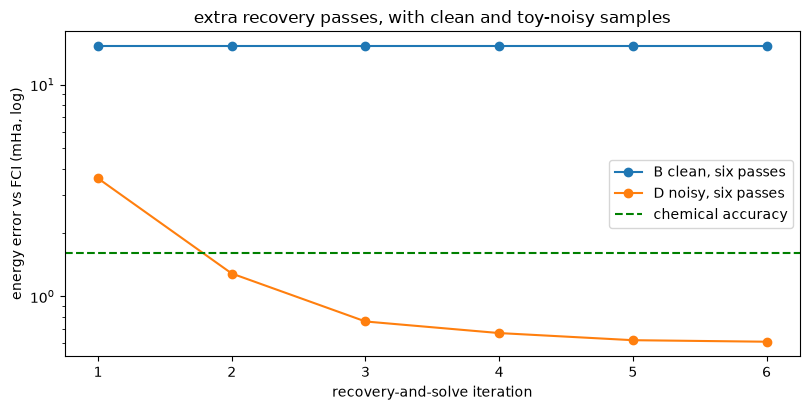

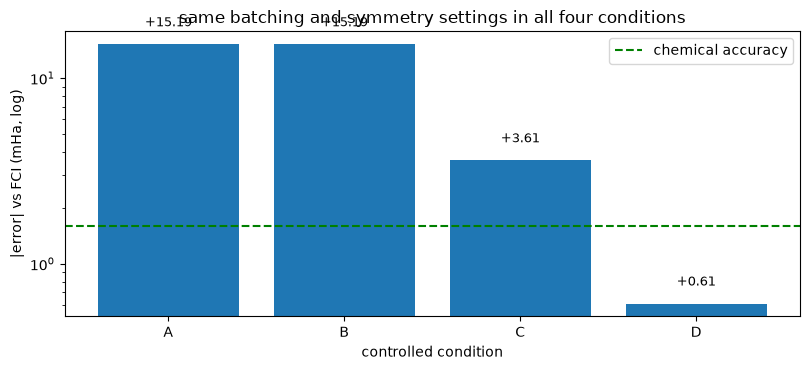

extra-pass improvement on clean samples (A - B): +0.000 mHa
extra-pass improvement on noisy samples (C - D): +2.995 mHa
In this seeded run, repaired noisy data finishes below repaired clean data.
Treat that as an observed outcome, not evidence that noise is generally beneficial.


In [12]:
def print_condition_table(conditions):
    print("\ncondition | distinct sampled rows | final alpha x beta shape | determinant dimension | error (mHa)")
    print("-" * 103)
    for key in ["A", "B", "C", "D"]:
        item = conditions[key]
        error_text = "n/a" if item["error_mha"] is None else f"{item['error_mha']:+10.3f}"
        print(f"{key:^9} | {item['distinct_sample_rows']:^21,} | "
              f"{str(item['final_shape']):^24} | {item['final_dimension']:^21,} | {error_text}")


print_condition_table(conditions)

fig, ax = plt.subplots(figsize=(8.2, 4.2))
for key in ["B", "D"]:
    history_errors = [max((entry["energy"] - e_fci) * 1000, 1e-10)
                      for entry in conditions[key]["history"]]
    ax.semilogy(range(1, len(history_errors) + 1), history_errors, "o-",
                label=conditions[key]["label"])
ax.axhline(1.6, color="green", ls="--", label="chemical accuracy")
ax.set_xlabel("recovery-and-solve iteration")
ax.set_ylabel("energy error vs FCI (mHa, log)")
ax.set_title("extra recovery passes, with clean and toy-noisy samples")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 3.8))
keys = ["A", "B", "C", "D"]
errors = [max(abs(conditions[key]["error_mha"]), 1e-10) for key in keys]
bars = ax.bar(keys, errors)
ax.set_yscale("log")
ax.axhline(1.6, color="green", ls="--", label="chemical accuracy")
for bar, key in zip(bars, keys):
    value = conditions[key]["error_mha"]
    ax.text(bar.get_x() + bar.get_width() / 2, max(abs(value), 1e-10) * 1.25,
            f"{value:+.2f}", ha="center", fontsize=9)
ax.set_xlabel("controlled condition")
ax.set_ylabel("|error| vs FCI (mHa, log)")
ax.set_title("same batching and symmetry settings in all four conditions")
ax.legend()
plt.tight_layout()
plt.show()

clean_recovery_gain = conditions["A"]["error_mha"] - conditions["B"]["error_mha"]
noisy_recovery_gain = conditions["C"]["error_mha"] - conditions["D"]["error_mha"]
print(f"extra-pass improvement on clean samples (A - B): {clean_recovery_gain:+.3f} mHa")
print(f"extra-pass improvement on noisy samples (C - D): {noisy_recovery_gain:+.3f} mHa")
if conditions["D"]["error_mha"] < conditions["B"]["error_mha"]:
    print("In this seeded run, repaired noisy data finishes below repaired clean data.")
    print("Treat that as an observed outcome, not evidence that noise is generally beneficial.")
else:
    print("In this seeded run, repaired clean data finishes at least as accurately as repaired noisy data.")

In [13]:
RUN_SPIN_SYMMETRY_COMPARISON = True

if RUN_SPIN_SYMMETRY_COMPARISON:
    symmetric_D = recover_and_diagonalize(
        problem,
        noisy_bit_array,
        label="noisy, six passes, spin-symmetrized",
        samples_per_batch=CONTROL_SETTINGS["samples_per_batch"],
        num_batches=CONTROL_SETTINGS["num_batches"],
        max_iterations=6,
        symmetrize_spin=True,
        seed=CONTROL_SETTINGS["seed"],
    )
    print(f"without spin symmetrization: {conditions['D']['error_mha']:+.3f} mHa, "
          f"dimension {conditions['D']['final_dimension']:,}")
    print(f"with spin symmetrization:    {symmetric_D['error_mha']:+.3f} mHa, "
          f"dimension {symmetric_D['final_dimension']:,}")
else:
    print("Spin-symmetry comparison skipped. Set RUN_SPIN_SYMMETRY_COMPARISON = True to run it.")

  noisy, six passes, spin-symmetrized, iteration 1: E = -107.580271 Ha | error   +1.21 mHa | batch dimensions [1600, 1600, 1600]
  noisy, six passes, spin-symmetrized, iteration 2: E = -107.581068 Ha | error   +0.41 mHa | batch dimensions [2116, 2116, 2116]
  noisy, six passes, spin-symmetrized, iteration 3: E = -107.581258 Ha | error   +0.22 mHa | batch dimensions [2304, 2304, 2304]
  noisy, six passes, spin-symmetrized, iteration 4: E = -107.581315 Ha | error   +0.17 mHa | batch dimensions [2401, 2401, 2401]
  noisy, six passes, spin-symmetrized, iteration 5: E = -107.581315 Ha | error   +0.17 mHa | batch dimensions [2401, 2401, 2401]
  noisy, six passes, spin-symmetrized, iteration 6: E = -107.581357 Ha | error   +0.13 mHa | batch dimensions [2500, 2500, 2500]
without spin symmetrization: +0.610 mHa, dimension 2,115
with spin symmetrization:    +0.126 mHa, dimension 2,500


In [14]:
# ✏️ =============== YOUR CODE HERE ===============
noisy5_bit_array = add_bit_flip_noise(
    bit_array, 0.05, seed=2027
)[0]

condition5 = recover_and_diagonalize(
    problem,
    noisy5_bit_array,
    label="5% toy noise, six passes",
    max_iterations=6,
    **CONTROL_SETTINGS,
    )
# ✏️ ============== END OF YOUR CODE ==============
assert noisy5_bit_array is not Ellipsis and condition5 is not Ellipsis, \
    "✏️ Build the 5% BitArray and run it through recover_and_diagonalize first."

noisy5_bools = bitstrings_to_bool(noisy5_bit_array.get_bitstrings())
valid5 = valid_electron_counts(noisy5_bools, norb, nelec).mean()
print(f"at 5% noise: {valid5:.0%} of rows retain both electron counts")
print(f"six-pass SQD error: {condition5['error_mha']:+.3f} mHa")
print("within chemical accuracy" if abs(condition5["error_mha"]) < 1.6
      else "above chemical accuracy in this seeded run")

  5% toy noise, six passes, iteration 1: E = -107.580179 Ha | error   +1.30 mHa | batch dimensions [1722, 1722, 1722]
  5% toy noise, six passes, iteration 2: E = -107.581172 Ha | error   +0.31 mHa | batch dimensions [2444, 2444, 2444]
  5% toy noise, six passes, iteration 3: E = -107.581285 Ha | error   +0.20 mHa | batch dimensions [2548, 2548, 2548]
  5% toy noise, six passes, iteration 4: E = -107.581352 Ha | error   +0.13 mHa | batch dimensions [2704, 2704, 2704]
  5% toy noise, six passes, iteration 5: E = -107.581352 Ha | error   +0.13 mHa | batch dimensions [2704, 2704, 2704]
  5% toy noise, six passes, iteration 6: E = -107.581380 Ha | error   +0.10 mHa | batch dimensions [2756, 2756, 2756]
at 5% noise: 48% of rows retain both electron counts
six-pass SQD error: +0.103 mHa
within chemical accuracy


In [15]:
def run_sqd(
    atom,
    *,
    basis="sto-3g",
    n_frozen=0,
    n_reps=2,
    shots=20_000,
    noise_p=0.02,
    samples_per_batch=500,
    num_batches=3,
    max_iterations=6,
    symmetrize_spin=False,
    seed=2026,
    compare_to_fci=True,
):
    """Coordinate the four teaching-stage helpers for a small closed-shell molecule."""
    problem = build_active_space_problem(
        atom, basis=basis, n_frozen=n_frozen, compare_to_fci=compare_to_fci
    )
    print_problem_summary(problem)
    circuit = build_ansatz(problem, n_reps=n_reps, measure=True)
    samples = sample_circuit(circuit, shots=shots, seed=seed)

    solve_samples = samples["bit_array"]
    noisy_bools = None
    if noise_p:
        solve_samples, noisy_bools = add_bit_flip_noise(solve_samples, noise_p, seed=seed + 1)

    sqd = recover_and_diagonalize(
        problem,
        solve_samples,
        label="run_sqd",
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        max_iterations=max_iterations,
        symmetrize_spin=symmetrize_spin,
        seed=seed + 2,
    )
    return {
        "problem": problem,
        "circuit": circuit,
        "samples": samples,
        "noisy_bools": noisy_bools,
        "sqd": sqd,
    }

In [16]:
water = [["O", (0.0, 0.0, 0.1173)],
         ["H", (0.0, 0.7572, -0.4692)],
         ["H", (0.0, -0.7572, -0.4692)]]

# ✏️ =============== YOUR CODE HERE ===============
h2o_frozen0 = run_sqd(
    water,
    basis="sto-3g",
    n_frozen=0,
    n_reps=2,
    shots=20_000,
    noise_p=0.02,
    max_iterations=6,
    seed=2026,
)

print("\nRunning SQD with 1 frozen orbital:\n")
h2o_frozen1 = run_sqd(
    water,
    basis="sto-3g",
    n_frozen=1,
    n_reps=2,
    shots=20_000,
    noise_p=0.02,
    max_iterations=6,
    seed=2026,
)
# ✏️ ============== END OF YOUR CODE ==============

active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.963023 Ha | error   +49.56 mHa
CCSD         : -75.012462 Ha | error    +0.12 mHa
exact (FCI)  : -75.012578 Ha
  run_sqd, iteration 1: E = -75.012476 Ha | error   +0.10 mHa | batch dimensions [182, 182, 182]
  run_sqd, iteration 2: E = -75.012482 Ha | error   +0.10 mHa | batch dimensions [238, 238, 238]
  run_sqd, iteration 3: E = -75.012490 Ha | error   +0.09 mHa | batch dimensions [255, 255, 255]
  run_sqd, iteration 4: E = -75.012506 Ha | error   +0.07 mHa | batch dimensions [304, 304, 304]
  run_sqd, iteration 5: E = -75.012537 Ha | error   +0.04 mHa | batch dimensions [288, 288, 288]
  run_sqd, iteration 6: E = -75.012537 Ha | error   +0.04 mHa | batch dimensions [288, 288, 288]

Running SQD with 1 frozen orbital:

active orbitals: 6 | electrons: (4, 4) | qubits: 12
Hartree-Fock : -74.963023 Ha | error   +49.48 mHa
CCSD         : -75.012383 Ha | error    +0.12 mHa
exact (FCI)  : -75.012500 Ha
  run_sqd, iteratio

In [17]:
lih = [
    ["Li", (0.0, 0.0, 0.0)],
    ["H",  (0.0, 0.0, 1.6)]
]

lih_test = run_sqd(
    lih,
    basis="sto-3g",
    n_frozen=0,
    n_reps=2,
    shots=20_000,
    noise_p=0.02,
    max_iterations=20,
    seed=2026,
)

active orbitals: 6 | electrons: (2, 2) | qubits: 12
Hartree-Fock : -7.861865 Ha | error   +20.46 mHa
CCSD         : -7.882314 Ha | error    +0.01 mHa
exact (FCI)  : -7.882324 Ha
  run_sqd, iteration 1: E = -7.882310 Ha | error   +0.01 mHa | batch dimensions [90, 90, 90]
  run_sqd, iteration 2: E = -7.882310 Ha | error   +0.01 mHa | batch dimensions [90, 90, 90]
  run_sqd, iteration 3: E = -7.882310 Ha | error   +0.01 mHa | batch dimensions [90, 90, 90]
  run_sqd, iteration 4: E = -7.882310 Ha | error   +0.01 mHa | batch dimensions [90, 90, 90]
  run_sqd, iteration 5: E = -7.882310 Ha | error   +0.01 mHa | batch dimensions [90, 90, 90]
  run_sqd, iteration 6: E = -7.882310 Ha | error   +0.01 mHa | batch dimensions [90, 90, 90]
  run_sqd, iteration 7: E = -7.882310 Ha | error   +0.01 mHa | batch dimensions [90, 90, 90]
  run_sqd, iteration 8: E = -7.882310 Ha | error   +0.01 mHa | batch dimensions [90, 90, 90]
  run_sqd, iteration 9: E = -7.882310 Ha | error   +0.01 mHa | batch dimension

In [18]:
print(lih_test.keys())

dict_keys(['problem', 'circuit', 'samples', 'noisy_bools', 'sqd'])


In [19]:
print(h2o_frozen0.keys())
print(lih_test.keys())

dict_keys(['problem', 'circuit', 'samples', 'noisy_bools', 'sqd'])
dict_keys(['problem', 'circuit', 'samples', 'noisy_bools', 'sqd'])


In [20]:
for name, result in [
    ("LiH", lih_test),
    ("H2O", h2o_frozen0),
]:
    print(f"\n{name}")
    print("SQD type:", type(result["sqd"]))

    sqd = result["sqd"]
    if isinstance(sqd, dict):
        print("SQD keys:", sqd.keys())
    elif hasattr(sqd, "__dict__"):
        print("SQD attributes:", vars(sqd).keys())


LiH
SQD type: <class 'dict'>
SQD keys: dict_keys(['label', 'result', 'energy', 'error_mha', 'history', 'distinct_sample_rows', 'final_shape', 'final_dimension', 'settings'])

H2O
SQD type: <class 'dict'>
SQD keys: dict_keys(['label', 'result', 'energy', 'error_mha', 'history', 'distinct_sample_rows', 'final_shape', 'final_dimension', 'settings'])


In [21]:

import inspect

print(inspect.getsource(run_sqd))


def run_sqd(
    atom,
    *,
    basis="sto-3g",
    n_frozen=0,
    n_reps=2,
    shots=20_000,
    noise_p=0.02,
    samples_per_batch=500,
    num_batches=3,
    max_iterations=6,
    symmetrize_spin=False,
    seed=2026,
    compare_to_fci=True,
):
    """Coordinate the four teaching-stage helpers for a small closed-shell molecule."""
    problem = build_active_space_problem(
        atom, basis=basis, n_frozen=n_frozen, compare_to_fci=compare_to_fci
    )
    print_problem_summary(problem)
    circuit = build_ansatz(problem, n_reps=n_reps, measure=True)
    samples = sample_circuit(circuit, shots=shots, seed=seed)

    solve_samples = samples["bit_array"]
    noisy_bools = None
    if noise_p:
        solve_samples, noisy_bools = add_bit_flip_noise(solve_samples, noise_p, seed=seed + 1)

    sqd = recover_and_diagonalize(
        problem,
        solve_samples,
        label="run_sqd",
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        max_itera

In [22]:
import time
import pandas as pd

# ==========================================
# EXPERIMENT 1: SHOT-COUNT STUDY
# ==========================================

# Shot counts to investigate
shot_counts = [5000, 10000, 20000, 25000, 30000]

# Molecules to test
molecules = {
    "H2O": water,
    "LiH": lih,
}

# Keep all other settings fixed so that
# shot count is the only variable.
experiment_settings = {
    "basis": "sto-3g",
    "n_frozen": 0,
    "n_reps": 2,
    "noise_p": 0.02,
    "max_iterations": 6,
    "seed": 2026,
}

# Store all results
shot_results = []

# Run each molecule at every shot count
for molecule_name, geometry in molecules.items():
    for shots in shot_counts:

        print(f"\nRunning {molecule_name} with {shots:,} shots")

        start_time = time.perf_counter()

        result = run_sqd(
            geometry,
            shots=shots,
            **experiment_settings,
        )

        runtime = time.perf_counter() - start_time

        # Retain the complete result for later analysis
        shot_results.append({
            "molecule": molecule_name,
            "shots": shots,
            "runtime_seconds": runtime,
            "result": result,
        })

        print(f"Completed in {runtime:.2f} seconds")

print("\nAll calculations completed.")
print(f"Total calculations: {len(shot_results)}")


# ==========================================
# CREATE A SUMMARY DATAFRAME
# ==========================================

shot_summary = pd.DataFrame([
    {
        "molecule": item["molecule"],
        "shots": item["shots"],
        "runtime_seconds": item["runtime_seconds"],
    }
    for item in shot_results
])

display(shot_summary)


# ==========================================
# EXPORT TO EXCEL (WITHOUT DOWNLOADING)
# ==========================================

excel_filename = "sqd_shot_study.xlsx"

with pd.ExcelWriter(excel_filename, engine="openpyxl") as writer:
    shot_summary.to_excel(
        writer,
        sheet_name="Shot Study",
        index=False,
    )

print(f"\nExcel file saved in the Colab session as: {excel_filename}")


Running H2O with 5,000 shots
active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.963023 Ha | error   +49.56 mHa
CCSD         : -75.012462 Ha | error    +0.12 mHa
exact (FCI)  : -75.012578 Ha
  run_sqd, iteration 1: E = -75.012318 Ha | error   +0.26 mHa | batch dimensions [156, 156, 156]
  run_sqd, iteration 2: E = -75.012509 Ha | error   +0.07 mHa | batch dimensions [196, 196, 196]
  run_sqd, iteration 3: E = -75.012509 Ha | error   +0.07 mHa | batch dimensions [196, 196, 196]
  run_sqd, iteration 4: E = -75.012509 Ha | error   +0.07 mHa | batch dimensions [196, 196, 196]
  run_sqd, iteration 5: E = -75.012509 Ha | error   +0.07 mHa | batch dimensions [196, 196, 196]
  run_sqd, iteration 6: E = -75.012509 Ha | error   +0.07 mHa | batch dimensions [196, 196, 196]
Completed in 1.47 seconds

Running H2O with 10,000 shots
active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.963023 Ha | error   +49.56 mHa
CCSD         : -75.012462 Ha | error    +0.12 mH

,molecule,shots,runtime_seconds
0,H2O,5000,1.469647
1,H2O,10000,3.078165
2,H2O,20000,2.147910
3,H2O,25000,1.265587
4,H2O,30000,1.378686
5,LiH,5000,0.795924
6,LiH,10000,1.165141
7,LiH,20000,1.451347
8,LiH,25000,1.230224
9,LiH,30000,1.055481



Excel file saved in the Colab session as: sqd_shot_study.xlsx


In [23]:

import inspect

print(inspect.getsource(run_sqd))


def run_sqd(
    atom,
    *,
    basis="sto-3g",
    n_frozen=0,
    n_reps=2,
    shots=20_000,
    noise_p=0.02,
    samples_per_batch=500,
    num_batches=3,
    max_iterations=6,
    symmetrize_spin=False,
    seed=2026,
    compare_to_fci=True,
):
    """Coordinate the four teaching-stage helpers for a small closed-shell molecule."""
    problem = build_active_space_problem(
        atom, basis=basis, n_frozen=n_frozen, compare_to_fci=compare_to_fci
    )
    print_problem_summary(problem)
    circuit = build_ansatz(problem, n_reps=n_reps, measure=True)
    samples = sample_circuit(circuit, shots=shots, seed=seed)

    solve_samples = samples["bit_array"]
    noisy_bools = None
    if noise_p:
        solve_samples, noisy_bools = add_bit_flip_noise(solve_samples, noise_p, seed=seed + 1)

    sqd = recover_and_diagonalize(
        problem,
        solve_samples,
        label="run_sqd",
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        max_itera

In [24]:

import inspect

print(inspect.getsource(recover_and_diagonalize))


def recover_and_diagonalize(
    problem,
    bit_array,
    *,
    label,
    samples_per_batch=500,
    num_batches=3,
    max_iterations=6,
    symmetrize_spin=False,
    seed=31415,
    verbose=True,
):
    """Run SQD and return a transparent record of energies and subspace dimensions."""
    history = []

    def callback(results):
        best = min(results, key=lambda result: result.energy)
        batch_shapes = [tuple(int(x) for x in result.sci_state.amplitudes.shape) for result in results]
        batch_dimensions = [int(np.prod(shape)) for shape in batch_shapes]
        total_energy = best.energy + problem["e_core"]
        history.append({
            "energy": total_energy,
            "batch_shapes": batch_shapes,
            "batch_dimensions": batch_dimensions,
        })
        if verbose:
            reference_text = ""
            if problem["e_fci"] is not None:
                reference_text = f" | error {(total_energy - problem['e_fci']) * 1000:+7.2f} mHa"
      

In [25]:

import time
import pandas as pd
import numpy as np

# ==========================================
# EXPERIMENT 2: SUBSPACE-SIZE STUDY
# ==========================================

# Keep the shot count fixed
fixed_shots = 20_000

# Test different batch configurations
subspace_settings = [
    {"samples_per_batch": 250, "num_batches": 2},
    {"samples_per_batch": 500, "num_batches": 2},
    {"samples_per_batch": 500, "num_batches": 3},
    {"samples_per_batch": 750, "num_batches": 3},
]

molecules = {
    "H2O": water,
    "LiH": lih,
}

# Store all full results
subspace_results = []
subspace_rows = []

for molecule_name, geometry in molecules.items():
    for setting_number, settings in enumerate(subspace_settings, start=1):

        print(
            f"\n{molecule_name} | Trial {setting_number} | "
            f"{settings['samples_per_batch']} samples/batch | "
            f"{settings['num_batches']} batches"
        )

        start_time = time.perf_counter()

        # Use the existing pipeline; do not modify run_sqd()
        result = run_sqd(
            geometry,
            basis="sto-3g",
            n_frozen=0,
            n_reps=2,
            shots=fixed_shots,
            noise_p=0.02,
            samples_per_batch=settings["samples_per_batch"],
            num_batches=settings["num_batches"],
            max_iterations=6,
            symmetrize_spin=False,
            seed=2026,
        )

        runtime = time.perf_counter() - start_time
        sqd = result["sqd"]

        # Save the full result for later analysis
        subspace_results.append({
            "molecule": molecule_name,
            "trial": setting_number,
            "settings": settings.copy(),
            "runtime_seconds": runtime,
            "result": result,
        })

        # Record the final results
        subspace_rows.append({
            "molecule": molecule_name,
            "trial": setting_number,
            "shots": fixed_shots,
            "samples_per_batch": settings["samples_per_batch"],
            "num_batches": settings["num_batches"],
            "energy_Ha": sqd["energy"],
            "FCI_error_mHa": sqd["error_mha"],
            "final_dimension": sqd["final_dimension"],
            "distinct_sample_rows": sqd["distinct_sample_rows"],
            "iterations_completed": len(sqd["history"]),
            "runtime_seconds": runtime,
        })

        print(f"Final SQD energy: {sqd['energy']:.6f} Ha")
        print(f"Final subspace dimension: {sqd['final_dimension']}")
        print(f"Runtime: {runtime:.2f} seconds")

# Create the summary table
subspace_summary = pd.DataFrame(subspace_rows)

print("\nEXPERIMENT 2 SUMMARY")
display(subspace_summary)

# ==========================================
# SAVE TO THE EXISTING EXCEL WORKBOOK
# ==========================================

excel_filename = "sqd_shot_study.xlsx"

try:
    # Preserve the existing Experiment 1 sheet
    with pd.ExcelWriter(
        excel_filename,
        engine="openpyxl",
        mode="a",
        if_sheet_exists="replace",
    ) as writer:
        subspace_summary.to_excel(
            writer,
            sheet_name="Subspace Study",
            index=False,
        )

except FileNotFoundError:
    # Create the workbook if it is not present in this session
    with pd.ExcelWriter(excel_filename, engine="openpyxl") as writer:
        subspace_summary.to_excel(
            writer,
            sheet_name="Subspace Study",
            index=False,
        )

print(f"\nExperiment 2 saved to the '{excel_filename}' workbook.")
print("The results remain in Colab; nothing has been downloaded.")



H2O | Trial 1 | 250 samples/batch | 2 batches
active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.963023 Ha | error   +49.56 mHa
CCSD         : -75.012462 Ha | error    +0.12 mHa
exact (FCI)  : -75.012578 Ha
  run_sqd, iteration 1: E = -75.012476 Ha | error   +0.10 mHa | batch dimensions [182, 182]
  run_sqd, iteration 2: E = -75.012482 Ha | error   +0.10 mHa | batch dimensions [238, 238]
  run_sqd, iteration 3: E = -75.012490 Ha | error   +0.09 mHa | batch dimensions [255, 255]
  run_sqd, iteration 4: E = -75.012506 Ha | error   +0.07 mHa | batch dimensions [304, 304]
  run_sqd, iteration 5: E = -75.012537 Ha | error   +0.04 mHa | batch dimensions [288, 288]
  run_sqd, iteration 6: E = -75.012537 Ha | error   +0.04 mHa | batch dimensions [288, 288]
Final SQD energy: -75.012537 Ha
Final subspace dimension: 288
Runtime: 1.13 seconds

H2O | Trial 2 | 500 samples/batch | 2 batches
active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.963023 Ha | error 

,molecule,trial,shots,samples_per_batch,num_batches,energy_Ha,FCI_error_mHa,final_dimension,distinct_sample_rows,iterations_completed,runtime_seconds
0,H2O,1,20000,250,2,-75.012537,0.041645,288,254,6,1.129927
1,H2O,2,20000,500,2,-75.012537,0.041645,288,254,6,1.115431
2,H2O,3,20000,500,3,-75.012537,0.041645,288,254,6,1.163970
3,H2O,4,20000,750,3,-75.012537,0.041645,288,254,6,1.185451
4,LiH,1,20000,250,2,-7.882310,0.013979,90,151,6,0.879378
5,LiH,2,20000,500,2,-7.882310,0.013979,90,151,6,0.876772
6,LiH,3,20000,500,3,-7.882310,0.013979,90,151,6,1.095286
7,LiH,4,20000,750,3,-7.882310,0.013979,90,151,6,1.311166



Experiment 2 saved to the 'sqd_shot_study.xlsx' workbook.
The results remain in Colab; nothing has been downloaded.


In [26]:

import time
import pandas as pd
import numpy as np

# ==========================================
# EXPERIMENT 3: REPEATABILITY STUDY
# ==========================================

# Fixed calculation settings
fixed_shots = 20_000
random_seeds = [11, 22, 33, 44, 55]

molecules = {
    "H2O": water,
    "LiH": lih,
}

repeat_results = []
repeat_rows = []

for molecule_name, geometry in molecules.items():
    for seed in random_seeds:

        print(f"\nRunning {molecule_name} with seed {seed}")

        start_time = time.perf_counter()

        result = run_sqd(
            geometry,
            basis="sto-3g",
            n_frozen=0,
            n_reps=2,
            shots=fixed_shots,
            noise_p=0.02,
            samples_per_batch=500,
            num_batches=3,
            max_iterations=6,
            symmetrize_spin=False,
            seed=seed,
        )

        runtime = time.perf_counter() - start_time
        sqd = result["sqd"]

        # Keep the full result for later analysis
        repeat_results.append({
            "molecule": molecule_name,
            "seed": seed,
            "runtime_seconds": runtime,
            "result": result,
        })

        # Record the measured values
        repeat_rows.append({
            "molecule": molecule_name,
            "seed": seed,
            "shots": fixed_shots,
            "energy_Ha": sqd["energy"],
            "FCI_error_mHa": sqd["error_mha"],
            "final_dimension": sqd["final_dimension"],
            "distinct_sample_rows": sqd["distinct_sample_rows"],
            "iterations_completed": len(sqd["history"]),
            "runtime_seconds": runtime,
        })

        print(f"SQD energy: {sqd['energy']:.6f} Ha")
        print(f"FCI error: {sqd['error_mha']} mHa")
        print(f"Runtime: {runtime:.2f} seconds")

# ==========================================
# RESULTS TABLE
# ==========================================

repeat_summary = pd.DataFrame(repeat_rows)

print("\nINDIVIDUAL RUNS")
display(repeat_summary)

# Calculate mean and standard deviation for each molecule
repeat_statistics = (
    repeat_summary.groupby("molecule")
    .agg(
        mean_energy_Ha=("energy_Ha", "mean"),
        std_energy_Ha=("energy_Ha", "std"),
        mean_absolute_FCI_error_mHa=(
            "FCI_error_mHa",
            lambda values: values.abs().mean()
        ),
        std_FCI_error_mHa=("FCI_error_mHa", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        mean_final_dimension=("final_dimension", "mean"),
    )
    .reset_index()
)

print("\nREPEATABILITY STATISTICS")
display(repeat_statistics)

# ==========================================
# SAVE TO THE EXISTING EXCEL WORKBOOK
# ==========================================

excel_filename = "sqd_shot_study.xlsx"

try:
    with pd.ExcelWriter(
        excel_filename,
        engine="openpyxl",
        mode="a",
        if_sheet_exists="replace",
    ) as writer:
        repeat_summary.to_excel(
            writer,
            sheet_name="Repeatability Runs",
            index=False,
        )
        repeat_statistics.to_excel(
            writer,
            sheet_name="Repeatability Stats",
            index=False,
        )

except FileNotFoundError:
    with pd.ExcelWriter(excel_filename, engine="openpyxl") as writer:
        repeat_summary.to_excel(
            writer,
            sheet_name="Repeatability Runs",
            index=False,
        )
        repeat_statistics.to_excel(
            writer,
            sheet_name="Repeatability Stats",
            index=False,
        )

print(f"\nExperiment 3 saved to {excel_filename}.")
print("The workbook remains in the Colab session.")



Running H2O with seed 11
active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.963023 Ha | error   +49.56 mHa
CCSD         : -75.012462 Ha | error    +0.12 mHa
exact (FCI)  : -75.012578 Ha
  run_sqd, iteration 1: E = -75.012459 Ha | error   +0.12 mHa | batch dimensions [195, 195, 195]
  run_sqd, iteration 2: E = -75.012459 Ha | error   +0.12 mHa | batch dimensions [210, 210, 210]
  run_sqd, iteration 3: E = -75.012459 Ha | error   +0.12 mHa | batch dimensions [225, 225, 225]
  run_sqd, iteration 4: E = -75.012492 Ha | error   +0.09 mHa | batch dimensions [238, 238, 238]
  run_sqd, iteration 5: E = -75.012524 Ha | error   +0.05 mHa | batch dimensions [272, 272, 272]
  run_sqd, iteration 6: E = -75.012524 Ha | error   +0.05 mHa | batch dimensions [272, 272, 272]
SQD energy: -75.012524 Ha
FCI error: 0.05404791266983011 mHa
Runtime: 2.19 seconds

Running H2O with seed 22
active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.963023 Ha | error   +49.56 mHa


,molecule,seed,shots,energy_Ha,FCI_error_mHa,final_dimension,distinct_sample_rows,iterations_completed,runtime_seconds
0,H2O,11,20000,-75.012524,0.054048,272,244,6,2.193976
1,H2O,22,20000,-75.012564,0.014521,289,260,6,1.175217
2,H2O,33,20000,-75.012570,0.008726,272,263,6,1.187699
3,H2O,44,20000,-75.012575,0.003254,306,245,6,1.227208
4,H2O,55,20000,-75.012487,0.091708,240,255,6,1.206515
5,LiH,11,20000,-7.882310,0.013979,90,147,6,0.923896
6,LiH,22,20000,-7.882311,0.013768,90,158,6,0.922134
7,LiH,33,20000,-7.882313,0.011755,99,153,6,1.128769
8,LiH,44,20000,-7.882311,0.013637,110,152,6,0.920173
9,LiH,55,20000,-7.882308,0.016007,81,158,6,0.942921



REPEATABILITY STATISTICS


,molecule,mean_energy_Ha,std_energy_Ha,mean_absolute_FCI_error_mHa,std_FCI_error_mHa,mean_runtime_seconds,mean_final_dimension
0,H2O,-75.012544,0.000038,0.034451,0.037731,1.398123,275.8
1,LiH,-7.882311,0.000002,0.013830,0.001509,0.967579,94.0



Experiment 3 saved to sqd_shot_study.xlsx.
The workbook remains in the Colab session.


In [27]:

import time
import pandas as pd
import numpy as np

# ==========================================
# EXPERIMENT 4: NOISE STUDY
# ==========================================

# Noise probabilities to investigate
noise_levels = [0.00, 0.01, 0.02, 0.05, 0.10]

# Keep all other settings fixed
fixed_shots = 20_000
fixed_seed = 2026

molecules = {
    "H2O": water,
    "LiH": lih,
}

noise_results = []
noise_rows = []

for molecule_name, geometry in molecules.items():
    for noise_p in noise_levels:

        print(
            f"\nRunning {molecule_name} "
            f"with noise probability {noise_p:.2f}"
        )

        start_time = time.perf_counter()

        result = run_sqd(
            geometry,
            basis="sto-3g",
            n_frozen=0,
            n_reps=2,
            shots=fixed_shots,
            noise_p=noise_p,
            samples_per_batch=500,
            num_batches=3,
            max_iterations=6,
            symmetrize_spin=False,
            seed=fixed_seed,
        )

        runtime = time.perf_counter() - start_time
        sqd = result["sqd"]

        # Retain full results for later analysis
        noise_results.append({
            "molecule": molecule_name,
            "noise_p": noise_p,
            "runtime_seconds": runtime,
            "result": result,
        })

        # Record results for the table
        noise_rows.append({
            "molecule": molecule_name,
            "noise_probability": noise_p,
            "shots": fixed_shots,
            "energy_Ha": sqd["energy"],
            "FCI_error_mHa": sqd["error_mha"],
            "final_dimension": sqd["final_dimension"],
            "distinct_sample_rows": sqd["distinct_sample_rows"],
            "iterations_completed": len(sqd["history"]),
            "runtime_seconds": runtime,
        })

        print(f"SQD energy: {sqd['energy']:.6f} Ha")
        print(f"FCI error: {sqd['error_mha']} mHa")
        print(f"Final dimension: {sqd['final_dimension']}")
        print(f"Runtime: {runtime:.2f} seconds")

# ==========================================
# DISPLAY RESULTS
# ==========================================

noise_summary = pd.DataFrame(noise_rows)

print("\nEXPERIMENT 4 SUMMARY")
display(noise_summary)

# ==========================================
# SAVE TO THE EXISTING EXCEL WORKBOOK
# ==========================================

excel_filename = "sqd_shot_study.xlsx"

try:
    with pd.ExcelWriter(
        excel_filename,
        engine="openpyxl",
        mode="a",
        if_sheet_exists="replace",
    ) as writer:
        noise_summary.to_excel(
            writer,
            sheet_name="Noise Study",
            index=False,
        )

except FileNotFoundError:
    with pd.ExcelWriter(excel_filename, engine="openpyxl") as writer:
        noise_summary.to_excel(
            writer,
            sheet_name="Noise Study",
            index=False,
        )

print(f"\nExperiment 4 saved to {excel_filename}.")
print("The workbook remains in the Colab session.")



Running H2O with noise probability 0.00
active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.963023 Ha | error   +49.56 mHa
CCSD         : -75.012462 Ha | error    +0.12 mHa
exact (FCI)  : -75.012578 Ha
  run_sqd, iteration 1: E = -75.000038 Ha | error  +12.54 mHa | batch dimensions [36, 36, 36]
  run_sqd, iteration 2: E = -75.000038 Ha | error  +12.54 mHa | batch dimensions [36, 36, 36]
  run_sqd, iteration 3: E = -75.000038 Ha | error  +12.54 mHa | batch dimensions [36, 36, 36]
  run_sqd, iteration 4: E = -75.000038 Ha | error  +12.54 mHa | batch dimensions [36, 36, 36]
  run_sqd, iteration 5: E = -75.000038 Ha | error  +12.54 mHa | batch dimensions [36, 36, 36]
  run_sqd, iteration 6: E = -75.000038 Ha | error  +12.54 mHa | batch dimensions [36, 36, 36]
SQD energy: -75.000038 Ha
FCI error: 12.54010849956444 mHa
Final dimension: 36
Runtime: 1.59 seconds

Running H2O with noise probability 0.01
active orbitals: 7 | electrons: (5, 5) | qubits: 14
Hartree-Fock : -74.9

,molecule,noise_probability,shots,energy_Ha,FCI_error_mHa,final_dimension,distinct_sample_rows,iterations_completed,runtime_seconds
0,H2O,0.00,20000,-75.000038,1.254011e+01,36,20,6,1.585342
1,H2O,0.01,20000,-75.012497,8.155513e-02,234,170,6,2.033736
2,H2O,0.02,20000,-75.012537,4.164462e-02,288,254,6,1.177062
3,H2O,0.05,20000,-75.012578,2.105153e-04,361,648,6,1.552809
4,H2O,0.10,20000,-75.012578,-4.519052e-08,441,1373,6,2.235154
5,LiH,0.00,20000,-7.881072,1.252335e+00,9,7,6,0.733469
6,LiH,0.01,20000,-7.882270,5.452761e-02,72,109,6,0.886593
7,LiH,0.02,20000,-7.882310,1.397935e-02,90,151,6,0.932259
8,LiH,0.05,20000,-7.882320,4.423369e-03,154,374,6,1.309546
9,LiH,0.10,20000,-7.882324,3.108624e-09,225,779,6,1.817617



Experiment 4 saved to sqd_shot_study.xlsx.
The workbook remains in the Colab session.


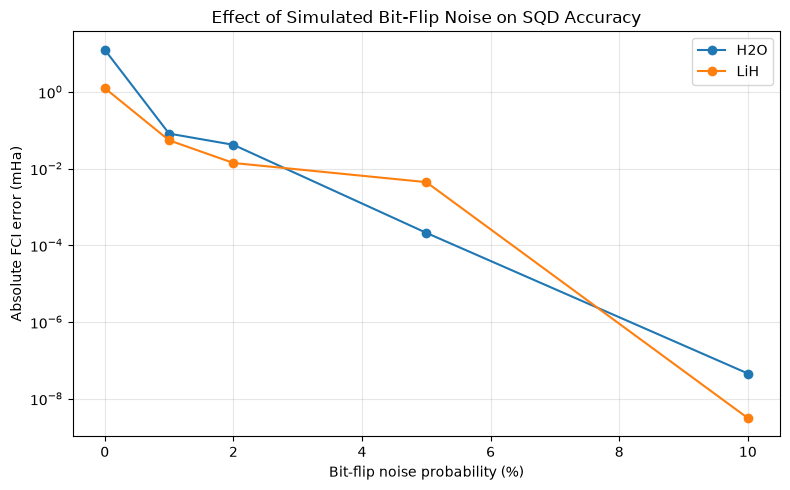

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the saved results
file = "sqd_shot_study.xlsx"
noise = pd.read_excel(file, sheet_name="Noise Study")

# Plot absolute FCI error
plt.figure(figsize=(8, 5))

for molecule in ["H2O", "LiH"]:
    data = noise[noise["molecule"] == molecule].sort_values(
        "noise_probability"
    )
    plt.plot(
        data["noise_probability"] * 100,
        data["FCI_error_mHa"].abs(),
        marker="o",
        label=molecule
    )

plt.yscale("log")
plt.xlabel("Bit-flip noise probability (%)")
plt.ylabel("Absolute FCI error (mHa)")
plt.title("Effect of Simulated Bit-Flip Noise on SQD Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("noise_study.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
from google.colab import files

# Matches the filename defined in your notebook
excel_filename = "sqd_shot_study.xlsx"

files.download(excel_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import glob
from google.colab import files

# Find all PNG image files saved in the current directory
image_files = glob.glob("*.png")

if not image_files:
    print("No PNG images found in the current directory. Make sure you saved them using plt.savefig().")
else:
    print(f"Found {len(image_files)} images. Starting downloads...")
    for img in image_files:
        print(f"Downloading: {img}")
        files.download(img)

Found 1 images. Starting downloads...
Downloading: noise_study.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>